# Tutorial: combinining values from multiple regions in the same cell

## Code setup

In [1]:
# Setting up paths to files:
import os
from dataclasses import dataclass

import numpy as np
import pandas as pd  # to load props dataframe
import json  # to load dict
import matplotlib.pyplot as plt

# Add path to package:
import sys
sys.path.insert(0,'../')
import isopods.grid
import isopods.convert

In [2]:
@dataclass(frozen=True)
class Paths:
    '''Singleton object for storing paths to data and database.'''

    dir_data: str = '../data'
    dict_filename: str = 'lsoa2011_devon_1k_grid_dict.json'
    grid_filename: str = 'lsoa2011_devon_1k_grid_df.csv'

paths = Paths()

## Load in grid data

In [3]:
# Grid dictionary:
p = os.path.join(paths.dir_data, paths.dict_filename)
with open(p, 'r') as f:
    transform_dict = json.load(f)

In [4]:
transform_dict

{'xmin': 212000.0,
 'ymax': 152000.0,
 'cell_width': 1000,
 'cell_height': 1000,
 'n_cols': 126,
 'n_rows': 118,
 'xmax': 338000.0,
 'ymin': 34000.0}

In [5]:
# Proportions dataframe:
p = os.path.join(paths.dir_data, paths.grid_filename)
# Use converters to turn proportion data from strings to lists.
converters = {
    'label_props': lambda x: (
        x.replace("'", '').replace(',', '')[1:-1].split()),
    'area_props': lambda x: [float(f) for f in x[1:-1].split()]
}
df_props = pd.read_csv(p, index_col=0, converters=converters)

# Confirm that contents are as expected:
for col in ['label_props', 'area_props']:
    print(col)
    print('Data type:', type(df_props.iloc[0][col]))
    print('List value type:', type(df_props.iloc[0][col][0]))

label_props
Data type: <class 'list'>
List value type: <class 'str'>
area_props
Data type: <class 'list'>
List value type: <class 'float'>


In [6]:
df_props.head(3)

,cell_row,cell_col,label_props,area_props,prop_cell_covered,label_majority,overlapping_polys
cell_label,,,,,,,
109,109,0,[E01020288],[1.0],0.000,E01020288,0
110,110,0,[E01020288],[1.0],0.124,E01020288,0
111,111,0,[E01020288],[1.0],0.089,E01020288,0


Invent some data for the LSOA. Assign each a random integer:

In [7]:
df_props[['label_props', 'area_props']].iloc[1856]

label_props    [E01020314, E01020329]
area_props             [0.889, 0.111]
Name: 5011, dtype: object

In [8]:
lsoa_here = np.sort(df_props['label_props'].explode('label_props').unique())
dict_region_value = dict(zip(lsoa_here,
                             np.random.randint(0, 11, len(lsoa_here))))

print(len(lsoa_here))

707


Pick out the labels of cells that contain many regions:

In [9]:
inds_many_labels = df_props[df_props['label_props'].str.len() > 3].index

## Scaled values

In [10]:
df_props['majority_area_value'] = (
    df_props['label_majority'].map(dict_region_value))

df_scaled_values = isopods.convert.calculate_scaled_cell_values(df_props, dict_region_value)
df_props = pd.concat((df_props, df_scaled_values), axis='columns')

Check the values for a cell that contains multiple regions:

In [11]:
df_props.loc[inds_many_labels[:5]]

,cell_row,cell_col,label_props,area_props,prop_cell_covered,label_majority,overlapping_polys,majority_area_value,area_value_scaled
cell_label,,,,,,,,,
3682,24,31,"[E01015142, E01015083, E01015150, E01015146, E...","[0.779, 0.178, 0.042, 0.0, 0.0]",0.310,E01015142,0,8,7.468
3751,93,31,"[E01020300, E01020295, E01020283, E01020281]","[0.52, 0.286, 0.14, 0.054]",1.000,E01020300,0,5,5.784
3752,94,31,"[E01020310, E01020295, E01020298, E01020300, E...","[0.686, 0.1, 0.09, 0.062, 0.062]",1.000,E01020310,0,8,7.732
3799,23,32,"[E01015145, E01015146, E01015039, E01015143, E...","[0.526, 0.276, 0.092, 0.056, 0.024, 0.017, 0.0...",0.901,E01015145,0,8,5.631
3800,24,32,"[E01015150, E01015083, E01015144, E01015149, E...","[0.281, 0.225, 0.155, 0.112, 0.1, 0.095, 0.025...",1.000,E01015150,0,4,4.492


Check the calculation:

In [12]:
cell_example = inds_many_labels[0]
labels_example = df_props.loc[cell_example, 'label_props']
props_example = df_props.loc[cell_example, 'area_props']
values_example = [dict_region_value[r] for r in labels_example]
scaled_area_example = df_props.loc[cell_example, 'area_value_scaled']

calc_val = sum([props_example[i] * values_example[i]
                for i in range(len(labels_example))])

calc_str = ' + '.join([f'{props_example[i]}x{values_example[i]}'
                       for i in range(len(labels_example))])
calc_str += f' = {calc_val:.3f}'
print(calc_str)

print(f'Result from function:           {scaled_area_example:.3f}')
print(f'Result from single calculation: {calc_val:.3f}')

0.779x8 + 0.178x6 + 0.042x4 + 0.0x4 + 0.0x8 = 7.468
Result from function:           7.468
Result from single calculation: 7.468


Check that the scaled values are within the range of the original data:

In [13]:
df_props[['majority_area_value', 'area_value_scaled']].describe().loc[['min', 'max']]

,majority_area_value,area_value_scaled
min,0.0,0.0
max,10.0,10.002


## Convert grids to array

Same method as the usual grids.

Convert to array using the transform dict:

In [14]:
# Only keep data where the cell is mostly covered:
mask = df_props['prop_cell_covered'] >= 0.5

arr_maj = isopods.convert.convert_df_to_2darray(
    df_props.loc[mask], 'majority_area_value', **transform_dict)
arr_scaled = isopods.convert.convert_df_to_2darray(
    df_props.loc[mask], 'area_value_scaled', **transform_dict)

Check a few grid values:

In [15]:
arr_maj[42:45, 20:30]

masked_array(
  data=[[--, --, --, --, --, --, --, 7, 7, 0],
        [--, --, --, --, --, --, --, 7, 7, 7],
        [--, --, --, --, --, 7, 7, 7, 7, 7]],
  mask=[[ True,  True,  True,  True,  True,  True,  True, False, False,
         False],
        [ True,  True,  True,  True,  True,  True,  True, False, False,
         False],
        [ True,  True,  True,  True,  True, False, False, False, False,
         False]],
  fill_value=999999)

In [16]:
arr_maj.dtype

dtype('int64')

In [17]:
arr_scaled[42:45, 20:30]

masked_array(
  data=[[--, --, --, --, --, --, --, 7.0, 5.8309999999999995, 0.91],
        [--, --, --, --, --, --, --, 7.0, 7.0, 4.291],
        [--, --, --, --, --, 7.0, 7.0, 7.0, 7.0, 7.0]],
  mask=[[ True,  True,  True,  True,  True,  True,  True, False, False,
         False],
        [ True,  True,  True,  True,  True,  True,  True, False, False,
         False],
        [ True,  True,  True,  True,  True, False, False, False, False,
         False]],
  fill_value=1e+20)

## Plot scaled grid

In [18]:
# For plotting the grid with imshow:
extent = (transform_dict['xmin'], transform_dict['xmax'],
          transform_dict['ymin'], transform_dict['ymax'])

Run the plots twice to show first all of Devon and then a zoom-in of the Exe estuary. In both cases the same data is plotted.

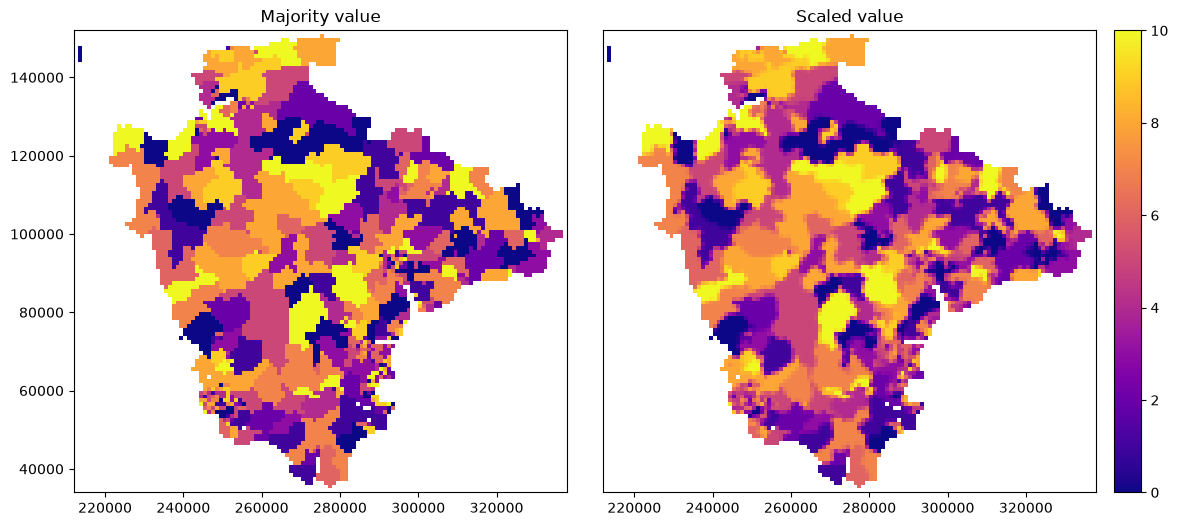

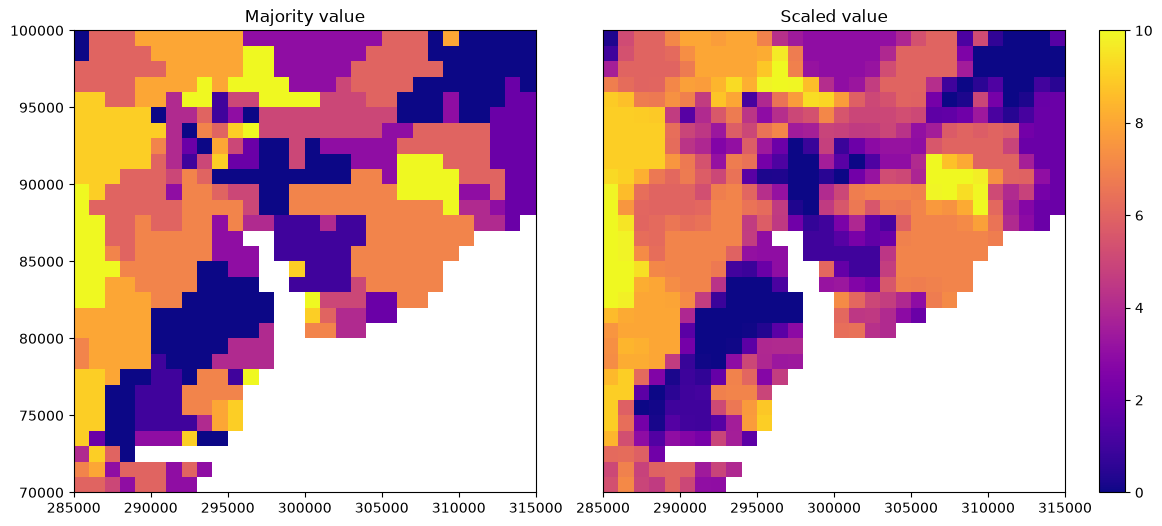

In [19]:
xlims = [[None, None], [285000, 315000]]
ylims = [[None, None], [70000, 100000]]

for j in range(2):
    gk = {'width_ratios': [20, 20, 1], 'wspace': 0.0}
    fig, axs = plt.subplots(1, 3, figsize=(14, 6), gridspec_kw=gk)
    for i, arr in enumerate([arr_maj, arr_scaled]):
        # Draw gridded data:
        cmap = plt.get_cmap('plasma')
        cl = axs[i].imshow(arr, origin='lower', extent=extent,
                           interpolation='None', cmap=cmap)
        if i == 1:
            # Only draw colourbar once - expect same for both ax.
            plt.colorbar(cl, cax=axs[-1])
        axs[i].set_xlim(xlims[j])
        axs[i].set_ylim(ylims[j])

    axs[1].set_yticks([])  # stop clash with other axis
    axs[0].set_title('Majority value')
    axs[1].set_title('Scaled value')
    plt.show()

Can see some softening of the region boundaries. The majority value map changes value sharply from one region to another, whereas the scaled grid has in-between values in cells that contain multiple regions.